# 14 — Əl ilə yazılmış payload siyahıları (PayloadsAllTheThings, fuzzdb)

**Sual:** sqlmap şablonlarında öyrədilmiş detektorlar insanların yazdığı, sqlmap formatında olmayan SQLi payload-larını tanıyırmı?

- Mənbələr (sabit commit, `src/handwritten.py`):
  - `swisskyrepo/PayloadsAllTheThings` — `SQL Injection/Intruder/*` (MIT);
  - `fuzzdb-project/fuzzdb` — `attack/sql-injection/**/*.txt` (BSD-3-Clause / CC BY 3.0).
  PayloadsAllTheThings-in Markdown fırıldaq vərəqləri (payload + izah qarışıqdır) istifadə olunmur, yalnız düz mətn siyahıları.
- Təmizləmə: TAB-dan sonrakı izah kəsilir, boş sətirlər və `# ...` şərhləri silinir, fuzzer yer tutucuları (`__TIME__`, `<username>` …) sabit dəyərlə əvəz olunur,
  SQL tokeni olmayan sətirlər (tək simvollar `'`, `%00`, tək sözlər `asc`, LDAP probları) çıxarılır, dublikatlar silinir.
- Model girişi = **ssenari A** (middleware bir dəfə URL decode edir): `Query = unquote(payload)`; dublikat da bu formada müəyyən olunur.
- Müstəqillik: train ilə tam / boşluq-normallaşdırılmış / tam normallaşdırılmış üst-üstə düşmə, ikiqat boşluq faizi, sqlmap şablonu (skelet) uyğunluğu.
  Hər seed üçün train+val ilə **normallaşdırılmış** formada üst-üstə düşən payload-lar testdən çıxarılır.
- Detektorlar 12 ilə eyni (eyni grid, eyni seed 42–46): LR / SVM / RF / NB baza, LR + normallaşdırma, LR + normallaşdırma + augmentation, qara siyahı ×2, libinjection.
- **FPR:** bu siyahılarda təmiz sinif yoxdur. FPR **HttpParamsDataset-in təmiz sinfində** (real veb form dəyərləri, train+val ilə üst-üstə düşənlər çıxarılıb) hesablanır.
- Obfuskasiya: alternativ whitespace (`src/obfuscation.py::alt_whitespace`, ssenari A) eyni payload-lara tətbiq olunur.

In [1]:
import hashlib, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import handwritten as hw
import libinj
import obfuscation as obf
from detectors import BL_INPUT, BL_SEARCH, GRID_BASE, GRID_DEF, LIBINJ, fit_tuned
from experiments import augment, leakage_free, load_clean, load_httpparams, make_split, rates
from normalize import normalize

RES, FIG = ROOT / "results", ROOT / "figures" / "paper"
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = [42, 43, 44, 45, 46]
clean, hp_all = load_clean(), load_httpparams()
print(len(clean), len(hp_all), "libinjection", libinj.VERSION)

30255 30156 libinjection 4.0.1


## 1. Yükləmə və təmizləmə

In [2]:
hw.fetch()
for name, r in hw.REPOS.items():
    got = hw.checked_out_commit(name)
    assert got == r["commit"], (name, got)
    print(f"{name:22s} {got}  {r['license']}")

kept, dropped = hw.build()
files = hw.source_files()
src_rows = []
for repo, rel, path in files:
    lines = hw._read_lines(path)
    d = dropped[(dropped.repo == repo) & (dropped.file == rel)].reason.value_counts()
    src_rows.append({"repo": repo, "file": rel, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()[:16],
                     "lines": len(lines), "empty": d.get("empty", 0), "comment": d.get("comment", 0),
                     "no_sql_token": d.get("no_sql_token", 0), "duplicate": d.get("duplicate", 0),
                     "kept_unique": int(((kept.repo == repo) & (kept.file == rel)).sum())})
sources = pd.DataFrame(src_rows)
total = sources.drop(columns=["repo", "file", "sha256"]).sum()
sources.loc[len(sources)] = {"repo": "CƏMİ", "file": "", "sha256": "", **total.to_dict()}
sources.to_csv(RES / "14_payload_sources.csv", index=False)
dropped.to_csv(RES / "14_payload_dropped.csv", index=False)
kept[["repo", "file", "line", "payload", "Query"]].to_csv(hw.PROCESSED, index=False)
print(f"saxlanılan unikal payload: {len(kept)}")
sources

PayloadsAllTheThings   08ea40e77db3f42ef8f20c65196f3936a19b6c86  MIT
fuzzdb                 5656ab25dc6bb43bae32236fab775658a90d7380  BSD-3-Clause / CC BY 3.0


saxlanılan unikal payload: 1427


,repo,file,sha256,lines,empty,comment,no_sql_token,duplicate,kept_unique
0,PayloadsAllTheThings,SQL Injection/Intruder/Auth_Bypass.txt,236969c5b9bd6b52,78,0,0,10,0,68
1,PayloadsAllTheThings,SQL Injection/Intruder/Auth_Bypass2.txt,da7f2e1159d0534e,121,0,0,4,8,109
2,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_MSSQL-WHERE_Time...,13567396b2e0057b,40,0,0,0,0,40
3,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_MSSQL.txt,2df3981c63ef2a4c,17,0,1,0,1,15
4,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_MSSQL_Enumeratio...,7f1825aa6c6b895c,15,0,4,0,0,11
5,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_MySQL-WHERE_Time...,b5794d86031d6383,45,0,0,0,0,45
6,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_MYSQL.txt,89bce04d45a522b1,6,0,0,1,0,5
7,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_MySQL_ReadLocalF...,be514dcda35c50d8,3,0,2,0,0,1
8,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_Oracle.txt,f1c407dc2f8401d1,56,1,1,0,1,53
9,PayloadsAllTheThings,SQL Injection/Intruder/FUZZDB_Postgres_Enumera...,97156d4f0b69e2e4,20,0,1,0,1,18


## 2. Müstəqillik yoxlaması
Seed 42 bölgüsünün train dəsti ilə (və müqayisə üçün bütün `clean_v2` ilə). Açarlar:
**tam** — eyni sətir; **boşluq** — kiçik hərf + boşluqların birləşdirilməsi (`group_key`, HttpParams sızma açarı);
**normallaşdırılmış** — `normalize()` (decode, şərhlər, whitespace, `( ) = ,` ətrafı);
**skelet** — normallaşdırılmış forma + rəqəmlər → 0, sətir literalları → `'s'` (sqlmap şablonları təsadüfi rəqəm/sətirlə doldurur).
Müqayisə üçün eyni göstəricilər bizim test dəstinin və HttpParams-ın zərərli sinfi üçün də verilir.

In [3]:
payloads = hw.load()
train42, val42, test42 = make_split(clean, 42)
tr_mal = train42[train42.Label == 1]
keys = {"exact": str, "ws": hw.ws_key, "norm": hw.norm_key}
train_sets = {k: set(train42.Query.map(f)) for k, f in keys.items()}
all_sets = {k: set(clean.Query.map(f)) for k, f in keys.items()}
skel_train_mal = set(tr_mal.Query.map(hw.skeleton))

def independence(name, q):
    q = pd.Series(list(q))
    row = {"set": name, "n": len(q)}
    for k, f in keys.items():
        fq = q.map(f)
        row[f"overlap_train_{k}_pct"] = 100 * fq.isin(train_sets[k]).mean()
        row[f"overlap_clean_v2_{k}_pct"] = 100 * fq.isin(all_sets[k]).mean()
    row["double_space_pct"] = 100 * q.str.contains("  ", regex=False).mean()
    row["sqlmap_skeleton_in_train_pct"] = 100 * q.map(hw.skeleton).isin(skel_train_mal).mean()
    row["median_len"] = q.str.len().median()
    return row

indep = pd.DataFrame([
    independence("Əl ilə yazılmış (hamısı)", payloads.Query),
    *[independence(f"  {r}", payloads.loc[payloads.repo == r, "Query"]) for r in hw.REPOS],
    independence("Bizim test, zərərli (seed 42)", test42.loc[test42.Label == 1, "Query"]),
    independence("HttpParams, zərərli", hp_all.loc[hp_all.Label == 1, "Query"]),
]).round(1)
indep.to_csv(RES / "14_independence.csv", index=False)
indep.set_index("set").T

set,Əl ilə yazılmış (hamısı),PayloadsAllTheThings,fuzzdb,"Bizim test, zərərli (seed 42)","HttpParams, zərərli"
n,1427.0,1286.0,141.0,1745.0,10852.0
overlap_train_exact_pct,1.8,0.9,9.9,0.0,2.4
overlap_clean_v2_exact_pct,2.2,1.0,13.5,100.0,3.6
overlap_train_ws_pct,2.0,0.9,12.8,0.0,2.4
overlap_clean_v2_ws_pct,2.6,1.0,17.0,100.0,3.6
overlap_train_norm_pct,7.5,4.4,36.2,0.1,55.3
overlap_clean_v2_norm_pct,10.7,6.6,48.2,100.0,79.1
double_space_pct,0.3,0.3,0.0,94.5,0.0
sqlmap_skeleton_in_train_pct,11.5,8.3,40.4,28.7,63.4
median_len,39.0,41.0,21.0,84.0,75.0


In [4]:
# Train ilə normallaşdırılmış formada üst-üstə düşən (seed 42-də testdən çıxarılan) payload-lar
ov = payloads[payloads.Query.map(hw.norm_key).isin(train_sets["norm"] | set(val42.Query.map(hw.norm_key)))]
print(len(ov), "payload çıxarılır (seed 42)")
ov[["file", "Query"]].head(20)

134 payload çıxarılır (seed 42)


,file,Query
5,SQL Injection/Intruder/Auth_Bypass.txt,""" or """"-"""
7,SQL Injection/Intruder/Auth_Bypass.txt,""" or """"&"""
8,SQL Injection/Intruder/Auth_Bypass.txt,""" or """"^"""
9,SQL Injection/Intruder/Auth_Bypass.txt,""" or """"*"""
10,SQL Injection/Intruder/Auth_Bypass.txt,or true--
11,SQL Injection/Intruder/Auth_Bypass.txt,""" or true--"
13,SQL Injection/Intruder/Auth_Bypass.txt,""") or true--"
18,SQL Injection/Intruder/Auth_Bypass.txt,""" or ""x""=""x"
19,SQL Injection/Intruder/Auth_Bypass.txt,""") or (""x"")=(""x"
20,SQL Injection/Intruder/Auth_Bypass.txt,""")) or ((""x""))=((""x"


## 3. Beş seed: bütün detektorlar
Hər seed üçün 12-dəki modellər eyni qaydada öyrədilir (baza: 02_v2 gridi; normallaşdırma və augmentation: 04 gridi).
- `recall_hw` — sızmasız əl ilə yazılmış payload-lar;
- `recall_hw_novel` — onlardan skeleti train-in zərərli skeletləri arasında **olmayanlar** (sqlmap şablonuna uyğun gəlməyən);
- `recall_hw_file_macro` — fayllar üzrə recall-un ortası (böyük `Generic_UnionSelect.txt` faylının çəkisini azaldır);
- `recall_hw_alt_whitespace` — alternativ whitespace (ssenari A), yalnız dəyişən payload-lar;
- `fpr_httpparams_clean` — HttpParams təmiz sinfi (sızmasız).

In [5]:
def hw_metrics(det, hwp, hw_aw, novel, hp_clean):
    p = det(hwp.Query)
    by_file = pd.Series(p).groupby(hwp.file.values).mean()
    return {"recall_hw": p.mean(), "recall_hw_novel": p[novel].mean(), "recall_hw_file_macro": by_file.mean(),
            "recall_hw_alt_whitespace": det(hw_aw).mean(), "fpr_httpparams_clean": det(hp_clean.Query).mean()}


def run_seed(s):
    t0 = time.perf_counter()
    rows = []
    add = lambda det, metric, value: rows.append({"seed": s, "detector": det, "metric": metric, "value": float(value)})
    train, val, test = make_split(clean, s)
    y = train.Label.to_numpy()
    hwp = hw.leakage_free_norm(payloads, train, val)
    novel = ~hwp.Query.map(hw.skeleton).isin(set(train.loc[train.Label == 1, "Query"].map(hw.skeleton))).to_numpy()
    aw = pd.DataFrame(obf.apply_technique("alt_whitespace", list(hwp.Query), seed=s))
    hw_aw = aw.loc[aw.changed, "obfuscated"]          # alt_whitespace yeni simvollar verir, unquote onu dəyişmir (ssenari A)
    hp = leakage_free(hp_all, train, val)
    hp_clean = hp[hp.Label == 0]
    for k, v in (("n_hw", len(hwp)), ("n_hw_removed_overlap", len(payloads) - len(hwp)), ("n_hw_novel", novel.sum()),
                 ("n_hw_alt_whitespace", len(hw_aw)), ("n_httpparams_clean", len(hp_clean))):
        add("meta", k, v)

    dets, vec = {}, None
    for name in ("LR", "SVM", "RF", "NB"):
        m, _, vec = fit_tuned(name, GRID_BASE[name], s, train.Query, y, val, vec=vec)
        dets[f"{name} baza"] = m.predict
    m, _, _ = fit_tuned("LR", GRID_DEF["LR"], s, train.Query, y, val, prep=normalize)
    dets["LR + normallaşdırma"] = m.predict
    aug = augment(train, s)
    m, _, _ = fit_tuned("LR", GRID_DEF["LR"], s, aug.Query, aug.Label.to_numpy(), val, prep=normalize)
    dets["LR + norm. + augmentation"] = m.predict
    dets.update({"Qara siyahı (sanitizeInput)": BL_INPUT, "Qara siyahı (sanitizeSearch)": BL_SEARCH,
                 "libinjection 4.0.1": LIBINJ})
    preds = {}
    for name, det in dets.items():
        for k, v in hw_metrics(det, hwp, hw_aw, novel, hp_clean).items():
            add(name, k, v)
        if s == 42:
            preds[name] = det(hwp.Query)
    print(f"seed {s}: n_hw={len(hwp)} ({time.perf_counter() - t0:.0f} s)")
    return rows, (hwp.assign(**{f"pred::{k}": v for k, v in preds.items()}) if s == 42 else None)


all_rows, pred42 = [], None
for s in SEEDS:
    r, p = run_seed(s)
    all_rows += r
    pred42 = p if p is not None else pred42
raw = pd.DataFrame(all_rows)
raw.to_csv(RES / "14_handwritten_raw.csv", index=False)

seed 42: n_hw=1293 (107 s)


seed 43: n_hw=1298 (133 s)


seed 44: n_hw=1301 (136 s)


seed 45: n_hw=1298 (132 s)


seed 46: n_hw=1297 (136 s)


### Seed 42 — 12 ilə uyğunluq (HttpParams FPR eyni modellərdən gəlməlidir)

In [6]:
r12 = pd.read_csv(RES / "12_multiseed_raw.csv")
r12 = r12[(r12.table == "HTTPPARAMS") & (r12.metric == "fpr")].set_index(["seed", "model"]).value
name12 = {"LR baza": "LR baza", "RF baza": "RF baza", "SVM baza": "SVM baza", "LR + normallaşdırma": "LR + normallaşdırma",
          "LR + norm. + augmentation": "LR + norm. + augmentation", "libinjection 4.0.1": "libinjection 4.0.1",
          "Qara siyahı (sanitizeInput)": "Qara siyahı (sanitizeInput)"}
here = raw[raw.metric == "fpr_httpparams_clean"].set_index(["seed", "detector"]).value
chk = pd.DataFrame([{"seed": s, "detector": d, "fpr_12": r12[(s, m)], "fpr_14": here[(s, d)]}
                    for s in SEEDS for d, m in name12.items()])
chk["abs_diff"] = (chk.fpr_12 - chk.fpr_14).abs()
chk.to_csv(RES / "14_reproduction_check.csv", index=False)
print("maks. fərq:", chk.abs_diff.max())

maks. fərq: 0.0


## 4. Nəticələr (orta ± std, 5 seed)

In [7]:
DET_ORDER = ["LR baza", "SVM baza", "RF baza", "NB baza", "LR + normallaşdırma", "LR + norm. + augmentation",
             "Qara siyahı (sanitizeInput)", "Qara siyahı (sanitizeSearch)", "libinjection 4.0.1"]
METRICS = ["recall_hw", "recall_hw_novel", "recall_hw_file_macro", "recall_hw_alt_whitespace", "fpr_httpparams_clean"]
a = raw[raw.detector != "meta"].groupby(["detector", "metric"]).value.agg(["mean", "std", "min", "max"]) * 100
a.round(3).to_csv(RES / "14_handwritten_mean_std.csv")
pm = lambda d: d["mean"].map("{:.2f}".format) + " ± " + d["std"].map("{:.2f}".format)
table = pm(a).unstack("metric").loc[DET_ORDER, METRICS]
table.to_csv(RES / "14_handwritten_table.csv")
meta = raw[raw.detector == "meta"].groupby("metric").value.agg(["mean", "std", "min", "max"])
meta.to_csv(RES / "14_handwritten_counts.csv")
display(meta)
table

,mean,std,min,max
metric,,,,
n_httpparams_clean,13182.4,11.865918,13163.0,13191.0
n_hw,1297.4,2.880972,1293.0,1301.0
n_hw_alt_whitespace,1241.6,2.509980,1238.0,1245.0
n_hw_novel,1244.0,4.743416,1238.0,1251.0
n_hw_removed_overlap,129.6,2.880972,126.0,134.0


metric,recall_hw,recall_hw_novel,recall_hw_file_macro,recall_hw_alt_whitespace,fpr_httpparams_clean
detector,,,,,
LR baza,92.79 ± 2.29,92.59 ± 2.37,79.98 ± 2.24,81.83 ± 2.66,0.02 ± 0.01
SVM baza,93.62 ± 1.52,93.39 ± 1.55,81.44 ± 1.04,83.65 ± 2.46,0.03 ± 0.02
RF baza,84.77 ± 1.45,84.33 ± 1.46,68.31 ± 1.48,35.59 ± 10.00,0.01 ± 0.00
NB baza,91.24 ± 0.33,91.21 ± 0.37,75.10 ± 1.98,91.04 ± 0.39,29.28 ± 0.25
LR + normallaşdırma,95.10 ± 0.67,95.02 ± 0.72,82.96 ± 1.03,95.20 ± 0.69,0.02 ± 0.01
LR + norm. + augmentation,95.16 ± 1.20,95.07 ± 1.26,82.87 ± 0.85,95.26 ± 1.27,0.02 ± 0.01
Qara siyahı (sanitizeInput),98.06 ± 0.03,98.02 ± 0.07,98.82 ± 0.02,98.87 ± 0.00,8.56 ± 0.09
Qara siyahı (sanitizeSearch),89.18 ± 0.14,89.00 ± 0.13,92.57 ± 1.73,89.84 ± 0.13,0.24 ± 0.01
libinjection 4.0.1,58.29 ± 0.14,57.44 ± 0.15,64.37 ± 1.23,57.10 ± 0.11,0.00 ± 0.00


In [8]:
# Fayl üzrə recall (seed 42) və LR + norm. + augmentation-ın buraxdığı payload-lar
pc = [c for c in pred42.columns if c.startswith("pred::")]
by_file = pred42.groupby(["repo", "file"])[pc].mean().mul(100).round(1)
by_file.columns = [c[6:] for c in pc]
by_file.insert(0, "n", pred42.groupby(["repo", "file"]).size())
by_file.to_csv(RES / "14_recall_by_file_seed42.csv")
missed = pred42.loc[pred42["pred::LR + norm. + augmentation"] == 0, ["file", "Query"] + pc]
missed.to_csv(RES / "14_missed_lr_norm_aug_seed42.csv", index=False)
print(len(missed), "buraxılmış (LR + norm. + aug., seed 42)")
by_file

48 buraxılmış (LR + norm. + aug., seed 42)


n  \
repo                 file                                                      
PayloadsAllTheThings SQL Injection/Intruder/Auth_Bypass.txt               17   
                     SQL Injection/Intruder/Auth_Bypass2.txt             105   
                     SQL Injection/Intruder/FUZZDB_MSSQL-WHERE_Time.txt   40   
                     SQL Injection/Intruder/FUZZDB_MSSQL.txt              15   
                     SQL Injection/Intruder/FUZZDB_MSSQL_Enumeration...   11   
                     SQL Injection/Intruder/FUZZDB_MYSQL.txt               1   
                     SQL Injection/Intruder/FUZZDB_MySQL-WHERE_Time.txt   45   
                     SQL Injection/Intruder/FUZZDB_MySQL_ReadLocalFi...    1   
                     SQL Injection/Intruder/FUZZDB_Oracle.txt             52   
                     SQL Injection/Intruder/FUZZDB_Postgres_Enumerat...   17   
                     SQL Injection/Intruder/Generic_ErrorBased.txt       150   
                     SQL Injection/Intruder/Generic_Fuzz.txt               4   
                     SQL Injection/Intruder/Generic_TimeBased.txt         96   
                     SQL Injection/Intruder/Generic_UnionSelect.txt      418   
                     SQL Injection/Intruder/SQL-Injection                 37   
                     SQL Injection/Intruder/SQLi_Polyglots.txt             2   
                     SQL Injection/Intruder/payloads-sql-blind-MSSQL...   95   
                     SQL Injection/Intruder/payloads-sql-blind-MySQL...   90   
                     SQL Injection/Intruder/payloads-sql-blind-MySQL...   18   
fuzzdb               attack/sql-injection/detect/MSSQL.txt                 2   
                     attack/sql-injection/detect/MSSQL_blind.txt           8   
                     attack/sql-injection/detect/MySQL.txt                 3   
                     attack/sql-injection/detect/MySQL_MSSQL.txt           1   
                     attack/sql-injection/detect/xplatform.txt            49   
                     attack/sql-injection/exploit/db2-enumeration.txt     12   
                     attack/sql-injection/exploit/mysql-injection-lo...    4   

                                                                         LR baza  \
repo                 file                                                          
PayloadsAllTheThings SQL Injection/Intruder/Auth_Bypass.txt                100.0   
                     SQL Injection/Intruder/Auth_Bypass2.txt                93.3   
                     SQL Injection/Intruder/FUZZDB_MSSQL-WHERE_Time.txt    100.0   
                     SQL Injection/Intruder/FUZZDB_MSSQL.txt                86.7   
                     SQL Injection/Intruder/FUZZDB_MSSQL_Enumeration...     45.5   
                     SQL Injection/Intruder/FUZZDB_MYSQL.txt               100.0   
                     SQL Injection/Intruder/FUZZDB_MySQL-WHERE_Time.txt    100.0   
                     SQL Injection/Intruder/FUZZDB_MySQL_ReadLocalFi...      0.0   
                     SQL Injection/Intruder/FUZZDB_Oracle.txt               96.2   
                     SQL Injection/Intruder/FUZZDB_Postgres_Enumerat...      0.0   
                     SQL Injection/Intruder/Generic_ErrorBased.txt          84.0   
                     SQL Injection/Intruder/Generic_Fuzz.txt               100.0   
                     SQL Injection/Intruder/Generic_TimeBased.txt           90.6   
                     SQL Injection/Intruder/Generic_UnionSelect.txt         99.8   
                     SQL Injection/Intruder/SQL-Injection                   83.8   
                     SQL Injection/Intruder/SQLi_Polyglots.txt             100.0   
                     SQL Injection/Intruder/payloads-sql-blind-MSSQL...    100.0   
                     SQL Injection/Intruder/payloads-sql-blind-MySQL...    100.0   
                     SQL Injection/Intruder/payloads-sql-blind-MySQL...    100.0   
fuzzdb               attack/sql-injection/detect/MSSQL.txt            

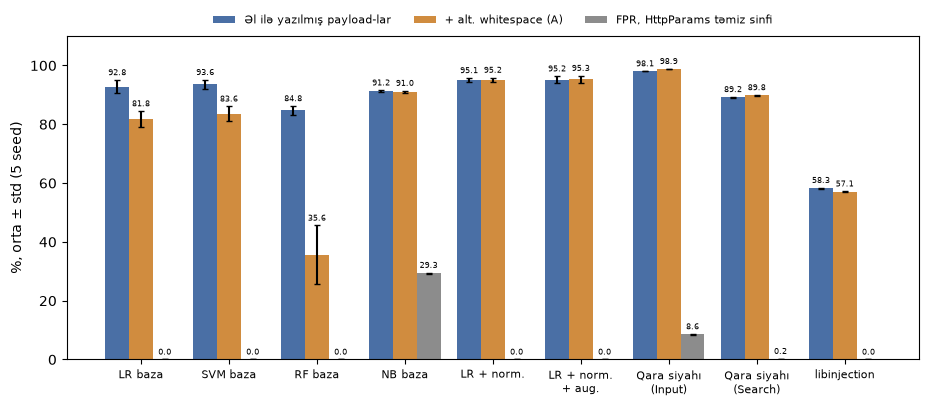

In [9]:
labels = ["LR baza", "SVM baza", "RF baza", "NB baza", "LR + norm.", "LR + norm.\n+ aug.", "Qara siyahı\n(Input)",
          "Qara siyahı\n(Search)", "libinjection"]
series = [("recall_hw", "Əl ilə yazılmış payload-lar", "#4a6fa5"),
          ("recall_hw_alt_whitespace", "+ alt. whitespace (A)", "#d08c3f"),
          ("fpr_httpparams_clean", "FPR, HttpParams təmiz sinfi", "#8c8c8c")]
fig, ax = plt.subplots(figsize=(11, 4.2))
x, w = np.arange(len(DET_ORDER)), 0.27
for i, (metric, lab, col) in enumerate(series):
    m = a.xs(metric, level="metric").loc[DET_ORDER]
    b = ax.bar(x + (i - 1) * w, m["mean"], w, yerr=m["std"], capsize=2, label=lab, color=col)
    ax.bar_label(b, fmt="%.1f", fontsize=6, padding=2)
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylabel("%, orta ± std (5 seed)")
ax.set_ylim(0, 110)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=8)
fig.savefig(FIG / "14_handwritten_recall.png", dpi=300, bbox_inches="tight")
plt.show()